# Gold forecasting with XGBoost

A separate model learns each horizon's log price change from the origin price.
Lagged gold values, trailing statistics and optional external features are tabular inputs.
Native tree missing-value handling avoids global imputation. Boosting rounds are tuned on inner
forecasting validation; outer blocks are never used for early stopping.

Run notebook 01 first. Review the shared audit and release assumptions before interpreting errors.

In [1]:
from pathlib import Path
import os
# Limit CPU threads before importing optional numerical/model libraries.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from gold_common_utils import ROOT, load_config
# Load the shared experiment configuration.
cfg = load_config()
pd.set_option('display.max_columns', 20)
print('Project:', ROOT)
print('Target:', cfg['target_name'], '| horizons:', cfg['horizons'])

Project: /home/kosala/git-repos/exps/gold_forecasting
Target: Kitco Price (USD) | horizons: [1, 5, 20]


## 1. Load the shared panel and evaluation contract

In [2]:
from gold_common_utils import load_prepared, feature_columns, forecast_origins, metrics
from gold_model_utils import (DEFAULT_TRIALS, run_cross_validation, evaluate_holdout,
                              refit_and_forecast, fit_model, predict_model)
KIND = 'xgboost'
# Reuse the processed data and folds created by notebook 01.
panel, features, folds = load_prepared()
display(folds)
print('Observed target:', panel.y.notna().sum())

,fold,cutoff,stop
0,cv_1,2175,2301
1,cv_2,2301,2427
2,cv_3,2427,2553
3,cv_4,2553,2679
4,cv_5,2679,2805
5,holdout,2805,3057


Observed target: 2646


## 2. Inspect input feature groups and candidate settings
`gold_only` establishes whether external factors improve an already useful gold-history model.
The initial search is intentionally small; expand it using development results only.
All candidate selection uses earlier inner validation. Read the adapters in `gold_model_utils.py`
for the explicit training and prediction logic.

In [3]:
# Show the exact candidates and the feature columns used per group.
trials = [dict(trial) for trial in DEFAULT_TRIALS[KIND]]
display(pd.DataFrame(trials))
for group in ['gold_only', 'external']:
    print(group, feature_columns(features, group, KIND))
# Change this local list to add candidates; keep comparable GRU/LSTM budgets.

,group,max_depth,n_estimators
0,gold_only,2,250
1,external,2,250
2,external,3,400


gold_only ['gold_latest', 'gold_missing', 'gold_lag_1', 'gold_lag_2', 'gold_lag_5', 'gold_lag_10', 'gold_lag_20', 'gold_lag_60', 'gold_ret_5', 'gold_vol_5', 'gold_mean_ratio_5', 'gold_ret_20', 'gold_vol_20', 'gold_mean_ratio_20', 'gold_ret_60', 'gold_vol_60', 'gold_mean_ratio_60', 'weekday', 'year_sin', 'year_cos']
external ['gold_latest', 'gold_missing', 'gold_lag_1', 'gold_lag_2', 'gold_lag_5', 'gold_lag_10', 'gold_lag_20', 'gold_lag_60', 'gold_ret_5', 'gold_vol_5', 'gold_mean_ratio_5', 'gold_ret_20', 'gold_vol_20', 'gold_mean_ratio_20', 'gold_ret_60', 'gold_vol_60', 'gold_mean_ratio_60', 'weekday', 'year_sin', 'year_cos', 'dxy', 'fed', 'yield10', 'cpi_yoy', 'cpi_mom', 'gpr_ma7', 'gpr_acts_ma7', 'gpr_threats_ma7', 'brent_spot', 'wti', 'yield_spread', 'dxy_age_days', 'gpr_ma7_age_days', 'wti_missing']


## 3. Check supervised labels and their dates

In [4]:
from gold_model_utils import supervised_rows
cutoff = int(folds.iloc[0].cutoff)
# Confirm the largest horizon's labels stay inside the training cutoff.
rows, log_changes = supervised_rows(panel, cutoff, cfg['horizons'][-1])
display(pd.DataFrame({'origin': panel.index[rows[-5:]],
                      'target_date': panel.index[rows[-5:] + cfg['horizons'][-1]],
                      'target_log_change': log_changes[-5:]}))
assert (rows + cfg['horizons'][-1] <= cutoff).all()

,origin,target_date,target_log_change
0,2023-05-04,2023-06-01,-0.038585
1,2023-05-08,2023-06-05,-0.035362
2,2023-05-09,2023-06-06,-0.029880
3,2023-05-10,2023-06-07,-0.035323
4,2023-05-11,2023-06-08,-0.045455


## 4. Run nested walk-forward development evaluation
This cell performs actual training and may take time. Each fold reports inner candidate scores,
selects a configuration, refits it, and predicts the outer block. Forecasting uses only information
available at each origin. Outer labels are used only for scoring.

For a quick installation check, use one fold and one candidate. Restore the full settings before
comparing models or making performance claims.

In [5]:
# Full defaults: five outer folds and all candidates above.
cv_folds = folds
# Full training; results are checkpointed to artifacts/<kind>/ after each fold.
cv_predictions, cv_metrics, selections = run_cross_validation(
    KIND, panel, features, cv_folds, cfg, trials=trials)
display(cv_metrics)
display(selections)

xgboost: cv_1; train through 2023-06-08
  candidate 1/3: inner MAE=44.007
  candidate 2/3: inner MAE=46.720
  candidate 3/3: inner MAE=47.287
xgboost: cv_2; train through 2023-12-01
  candidate 1/3: inner MAE=24.569
  candidate 2/3: inner MAE=28.313
  candidate 3/3: inner MAE=34.048
xgboost: cv_3; train through 2024-05-27
  candidate 1/3: inner MAE=55.081
  candidate 2/3: inner MAE=43.821
  candidate 3/3: inner MAE=48.280
xgboost: cv_4; train through 2024-11-19
  candidate 1/3: inner MAE=40.700
  candidate 2/3: inner MAE=33.469
  candidate 3/3: inner MAE=41.747
xgboost: cv_5; train through 2025-05-14
  candidate 1/3: inner MAE=81.705
  candidate 2/3: inner MAE=79.233
  candidate 3/3: inner MAE=81.393


,model,fold,horizon,n,MAE,RMSE,MAPE,MASE,baseline_MAE,skill_vs_persistence
0,xgboost,cv_1,1,5,13.597396,16.450154,0.692379,1.412824,9.580000,-0.419352
1,xgboost,cv_1,5,5,18.592170,29.742475,0.948618,1.931801,19.620000,0.052387
2,xgboost,cv_1,20,4,41.516066,45.177084,2.125392,4.313686,22.650000,-0.832939
3,xgboost,cv_2,1,5,11.647045,16.886441,0.569623,1.215345,11.254000,-0.034925
4,xgboost,cv_2,5,4,46.909946,60.829817,2.176988,4.894956,46.242500,-0.014434
5,xgboost,cv_2,20,6,106.685522,131.015406,4.703712,11.132413,76.023333,-0.403326
6,xgboost,cv_3,1,4,12.249814,14.326774,0.481327,1.255404,13.507500,0.093110
7,xgboost,cv_3,5,4,37.942354,47.365825,1.483466,3.888466,26.272500,-0.444185
8,xgboost,cv_3,20,4,50.216088,53.518303,2.046394,5.146322,55.287500,0.091728
9,xgboost,cv_4,1,4,23.917067,26.960783,0.861684,2.378922,26.072500,0.082671


,candidate,inner_MAE,params,fold
0,0,44.007500,"{""group"": ""gold_only"", ""max_depth"": 2, ""n_esti...",cv_1
1,1,46.719945,"{""group"": ""external"", ""max_depth"": 2, ""n_estim...",cv_1
2,2,47.286898,"{""group"": ""external"", ""max_depth"": 3, ""n_estim...",cv_1
3,0,24.568544,"{""group"": ""gold_only"", ""max_depth"": 2, ""n_esti...",cv_2
4,1,28.313395,"{""group"": ""external"", ""max_depth"": 2, ""n_estim...",cv_2
5,2,34.048023,"{""group"": ""external"", ""max_depth"": 3, ""n_estim...",cv_2
6,0,55.080838,"{""group"": ""gold_only"", ""max_depth"": 2, ""n_esti...",cv_3
7,1,43.820947,"{""group"": ""external"", ""max_depth"": 2, ""n_estim...",cv_3
8,2,48.280338,"{""group"": ""external"", ""max_depth"": 3, ""n_estim...",cv_3
9,0,40.700292,"{""group"": ""gold_only"", ""max_depth"": 2, ""n_esti...",cv_4


## 5. Review errors by horizon, baseline skill, and prediction bias

,MAE,RMSE,MAPE,MASE,skill_vs_persistence
horizon,,,,,
1,20.698820,24.720600,0.775193,2.049851,-0.087114
5,53.346613,68.128840,1.911718,5.328148,-0.040639
20,87.323101,106.214617,3.196194,8.742644,-0.150232


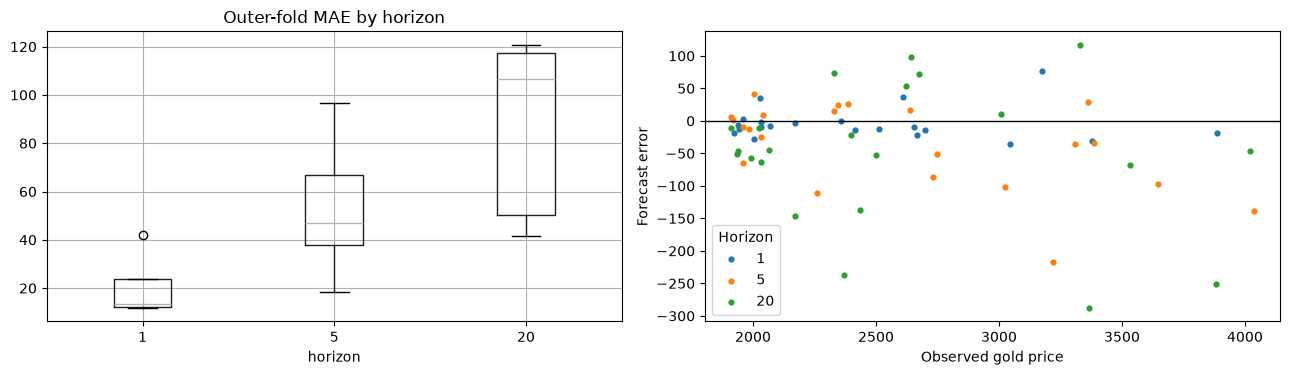

In [6]:
# Summarize outer error by horizon and check prediction bias per model.
display(cv_metrics.groupby('horizon')[['MAE', 'RMSE', 'MAPE', 'MASE', 'skill_vs_persistence']].mean())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cv_metrics.boxplot(column='MAE', by='horizon', ax=axes[0])
axes[0].set_title('Outer-fold MAE by horizon')
for horizon, group in cv_predictions.groupby('horizon'):
    observed = group.dropna(subset=['actual'])
    axes[1].scatter(observed.actual, observed.prediction - observed.actual, s=12, label=str(horizon))
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xlabel('Observed gold price')
axes[1].set_ylabel('Forecast error')
axes[1].legend(title='Horizon')
plt.suptitle('')
plt.tight_layout()

## 6. Lock the final configuration and evaluate the untouched holdout
The default is off so you can review development results first. Set
`final_holdout_enabled` to true in `config.json` when ready. This is an experiment guard,
not a request for additional permission. The function chooses parameters using development
history, records them before scoring, and preserves existing holdout results.

In [7]:
# Load the shared experiment configuration.
cfg = load_config()
# Holdout runs once, and parameters are locked before its results are scored.
if cfg['final_holdout_enabled']:
    holdout_predictions, holdout_metrics, locked_parameters = evaluate_holdout(
        KIND, panel, features, folds, cfg, trials=trials)
    display(holdout_metrics)
    display(locked_parameters)
else:
    print('Holdout not evaluated. Development predictions remain available for review.')

Holdout not evaluated. Development predictions remain available for review.


## 7. Refit the locked model and generate future forecasts
Run after the final holdout stage. The forecast starts from the latest observed gold quote.
Only the configured horizons are returned. Future actual external factors are not supplied.
Artifacts include the fitted model, input feature names, preprocessing where applicable,
locked configuration, predictions and metrics. No calibrated uncertainty intervals are claimed.

In [8]:
locked = ROOT / 'artifacts' / KIND / 'locked_parameters.json'
if cfg['final_holdout_enabled'] and locked.exists():
    # Refit reuses the locked configuration from artifacts/<kind>/locked_parameters.json.
    future_forecast = refit_and_forecast(KIND, panel, features, cfg)
    display(future_forecast)
else:
    print('Final refit waits for the parameter-lock stage.')

Final refit waits for the parameter-lock stage.
